# Лабораторная работа 2. Классификация данных и нейронные сети

## Датасет Titanic

В работе решается задача бинарной классификации: по сведениям о пассажире предсказать, выжил ли он при крушении «Титаника». Целевая переменная — Survived: 1 означает, что пассажир выжил, 0 — что не выжил.


## Цель и задачи

Цель работы — изучить методы классификации из библиотеки Scikit-learn, выполнить настройку гиперпараметров и построить нейронную сеть средствами TensorFlow с мониторингом в TensorBoard.

В работе выполняются следующие этапы:

1. Загрузка и анализ качества данных.
2. Подготовка признаков и корректное разделение на обучающую и тестовую выборки.
3. Сравнение восьми классических моделей, представляющих пять требуемых методов: наивный байесовский классификатор, дерево решений, линейный дискриминантный анализ, метод опорных векторов и k-ближайших соседей.
4. Подбор гиперпараметров по стратифицированной кросс-валидации.
5. Обучение нейронной сети TensorFlow и просмотр журналов обучения в TensorBoard.
6. Итоговое сравнение моделей на одной тестовой выборке.


## Как открыть и запустить в VS Code

Поместите файл Titanic-Dataset.csv в ту же папку, что и этот notebook. В VS Code выберите интерпретатор Python из своего виртуального окружения и запускайте ячейки сверху вниз.

Для классической части нужны пакеты pandas, numpy, matplotlib, seaborn и scikit-learn. Для блока нейронной сети дополнительно нужны tensorflow и tensorboard. Если их нет в выбранном окружении, в терминале VS Code выполните:

python -m pip install pandas numpy matplotlib seaborn scikit-learn tensorflow tensorboard

После установки перезапустите ядро notebook и выполните ячейки заново.


## Информация о выбранном датасете

Файл содержит 891 запись о пассажирах «Титаника» и 12 исходных столбцов. Задача относится к бинарной классификации.

| Столбец | Смысл |
|---|---|
| Name | Имя пассажира |
| Sex | Пол |
| Age | Возраст, лет |
| SibSp | Число братьев, сестёр и супругов на борту |
| Parch | Число родителей и детей на борту |
| Embarked | Порт посадки: C, Q или S |
| Ticket | Номер билета |
| Fare | Стоимость билета |
| Cabin | Номер каюты |
| PassengerId | Идентификатор пассажира |
| Pclass | Класс билета: 1, 2 или 3 |
| Survived | Целевая переменная: 1 — выжил, 0 — не выжил |


## Импорт библиотек для классической части


In [1]:
import os
import re
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

SEED = 42
N_JOBS = -1

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110


## Загрузка и первичный осмотр данных


In [2]:
DATA_PATH = Path("Titanic-Dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("upload") / "Titanic-Dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл Titanic-Dataset.csv не найден. Поместите его рядом с notebook."
    )

df_raw = pd.read_csv(DATA_PATH)

print("Путь к файлу:", DATA_PATH.resolve())
print("Размер таблицы (строки, столбцы):", df_raw.shape)
display(df_raw.head(10))


Путь к файлу: E:\Lab2_ML\Titanic-Dataset.csv
Размер таблицы (строки, столбцы): (891, 12)


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0
5,"Moran, Mr. James",male,NaN,0,0,Q,330877,8.4583,NaN,6,3,0
6,"McCarthy, Mr. Timothy J",male,54.0,0,0,S,17463,51.8625,E46,7,1,0
7,"Palsson, Master. Gosta Leonard",male,2.0,3,1,S,349909,21.0750,NaN,8,3,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,S,347742,11.1333,NaN,9,3,1
9,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,C,237736,30.0708,NaN,10,2,1


In [3]:
df_raw.info()
display(df_raw.describe(include="all").T.round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         891 non-null    object 
 1   Sex          891 non-null    object 
 2   Age          714 non-null    float64
 3   SibSp        891 non-null    int64  
 4   Parch        891 non-null    int64  
 5   Embarked     889 non-null    object 
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    object 
 9   PassengerId  891 non-null    int64  
 10  Pclass       891 non-null    int64  
 11  Survived     891 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
Cabin,204,147,G6,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0


В датасете 891 строка и 12 столбцов. Целевой столбец Survived имеет целочисленный тип. Числовые признаки включают возраст, стоимость билета и сведения о семье. Столбцы пола, порта посадки, имени, билета и каюты имеют категориальную или текстовую природу.


## Первичный анализ качества данных


In [4]:
quality = pd.DataFrame({
    "Тип данных": df_raw.dtypes.astype(str),
    "Число пропусков": df_raw.isna().sum(),
    "Доля пропусков, %": (df_raw.isna().mean() * 100).round(2),
    "Уникальных значений": df_raw.nunique(),
})
display(quality.sort_values("Число пропусков", ascending=False))

duplicate_count = int(df_raw.duplicated().sum())
print("Полных дубликатов:", duplicate_count)


,Тип данных,Число пропусков,"Доля пропусков, %",Уникальных значений
Cabin,object,687,77.10,147
Age,float64,177,19.87,88
Embarked,object,2,0.22,3
Name,object,0,0.00,891
SibSp,int64,0,0.00,7
Sex,object,0,0.00,2
Ticket,object,0,0.00,681
Parch,int64,0,0.00,7
Fare,float64,0,0.00,248
PassengerId,int64,0,0.00,891


Полных дубликатов: 0


Пропуски есть в трёх столбцах: Age — 177 значений (19,87 %), Cabin — 687 значений (77,10 %), Embarked — 2 значения (0,22 %). Полных дубликатов нет.

Удалять строки с пропусками нельзя: это привело бы к потере почти пятой части наблюдений из-за возраста и большей части выборки из-за каюты. Возраст и порт посадки будут заполнены внутри конвейера обучения, а из Cabin будет выделена только палуба. Отсутствующая палуба будет обозначена отдельной категорией U.


## Анализ целевой переменной


In [5]:
class_counts = df_raw["Survived"].value_counts().sort_index()
class_names = {0: "Не выжил (0)", 1: "Выжил (1)"}
class_table = pd.DataFrame({
    "Класс": [class_names[index] for index in class_counts.index],
    "Количество": class_counts.values,
    "Доля, %": (class_counts.values / len(df_raw) * 100).round(2),
})
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=class_table, x="Класс", y="Количество", ax=ax)
ax.set_title("Распределение целевой переменной Survived")
ax.set_xlabel("")
ax.set_ylabel("Число пассажиров")
for container in ax.containers:
    ax.bar_label(container)
plt.show()


,Класс,Количество,"Доля, %"
0,Не выжил (0),549,61.62
1,Выжил (1),342,38.38


<Figure size 770x440 with 1 Axes>

В выборке 549 пассажиров не выжили (61,62 %), а 342 выжили (38,38 %). Дисбаланс классов умеренный, поэтому одной Accuracy недостаточно. Далее одновременно используются Precision, Recall, F1, специфичность, Balanced Accuracy и ROC-AUC.


## Распределение исходных признаков


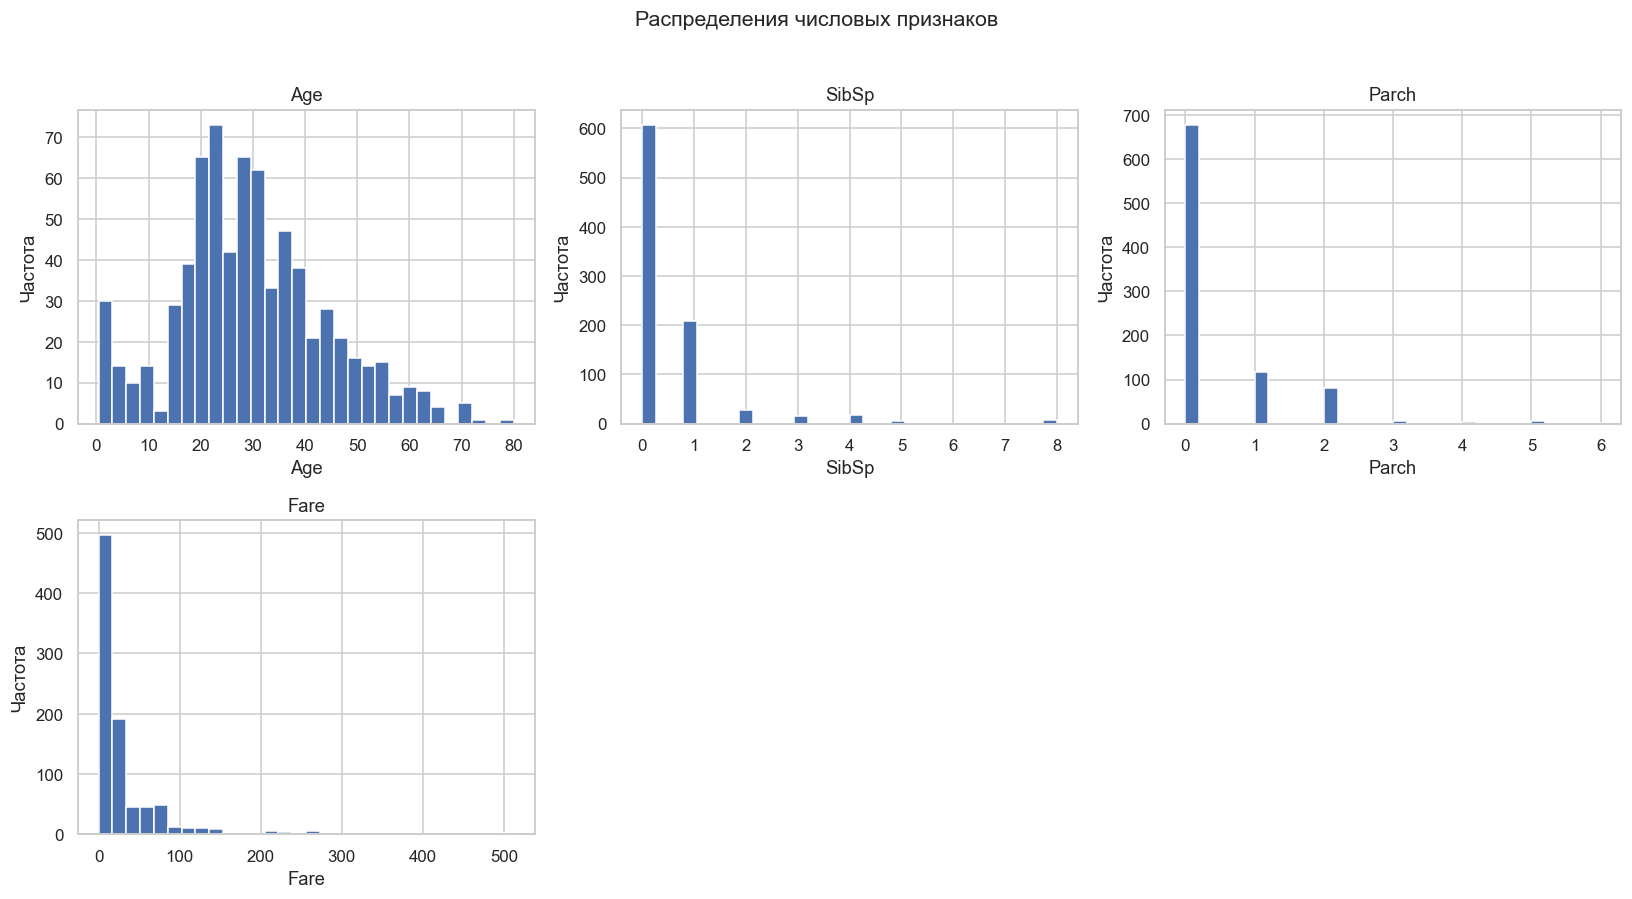

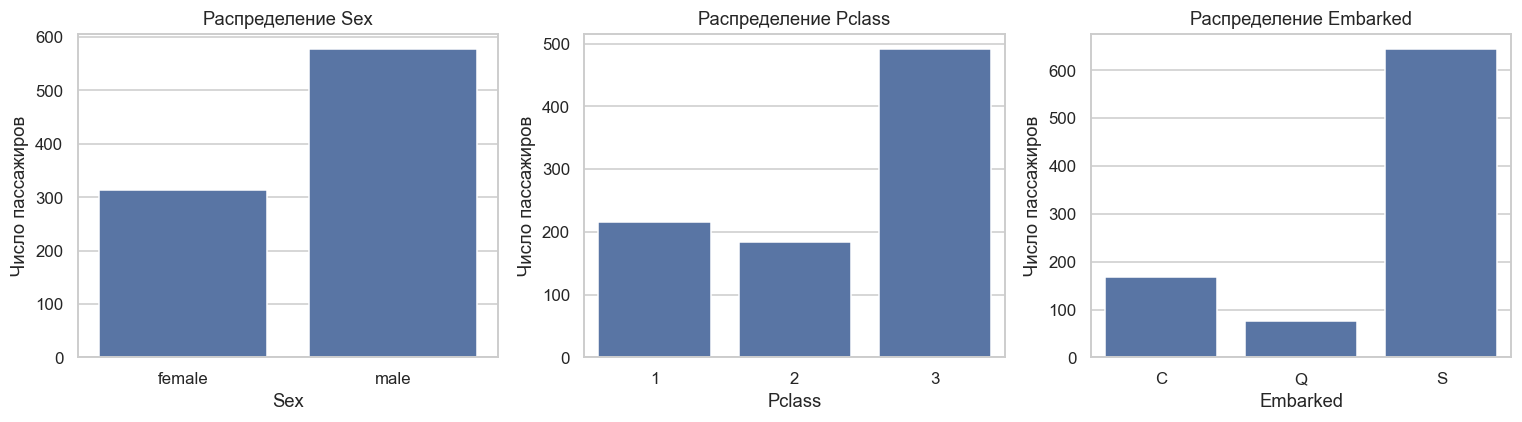

In [6]:
numeric_raw = ["Age", "SibSp", "Parch", "Fare"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, numeric_raw):
    ax.hist(df_raw[column].dropna(), bins=30, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Частота")
for ax in axes.flat[len(numeric_raw):]:
    ax.set_visible(False)
fig.suptitle("Распределения числовых признаков", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["Sex", "Pclass", "Embarked"]):
    order = sorted(df_raw[column].dropna().unique())
    sns.countplot(data=df_raw, x=column, order=order, ax=ax)
    ax.set_title(f"Распределение {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Число пассажиров")
plt.tight_layout()
plt.show()


Возраст и стоимость билета имеют пропуски или асимметрию, поэтому для возраста применяется медианная импутация, а стоимость билета преобразуется функцией log(1 + Fare). Пол, класс билета и порт посадки являются важными категориальными признаками и будут преобразованы методом one-hot encoding.


## Предобработка и конструирование признаков

Сырые Name, Ticket, Cabin и PassengerId не подаются в модель напрямую. Name, Ticket и PassengerId почти уникальны, поэтому они могут привести к запоминанию объектов вместо выявления закономерностей. Из Name извлекается социальное обращение Title, а из Cabin — палуба Deck. Также создаются размер семьи, индикатор одиночного путешествия и логарифм стоимости билета.


In [7]:
data = df_raw.drop_duplicates().reset_index(drop=True).copy()

data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.")[0].str.strip()
common_titles = ["Mr", "Miss", "Mrs", "Master"]
data["Title"] = data["Title"].where(data["Title"].isin(common_titles), "Rare")

data["Deck"] = data["Cabin"].fillna("U").astype(str).str[0].str.upper()
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
data["FareLog"] = np.log1p(data["Fare"])

numeric_features = ["Age", "SibSp", "Parch", "FareLog", "FamilySize", "IsAlone"]
categorical_features = ["Pclass", "Sex", "Embarked", "Title", "Deck"]
feature_columns = numeric_features + categorical_features

X = data[feature_columns].copy()
y = data["Survived"].astype(int).copy()

print("После удаления полных дубликатов:", data.shape)
print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
display(X.head())


После удаления полных дубликатов: (891, 17)
Числовые признаки: ['Age', 'SibSp', 'Parch', 'FareLog', 'FamilySize', 'IsAlone']
Категориальные признаки: ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck']


,Age,SibSp,Parch,FareLog,FamilySize,IsAlone,Pclass,Sex,Embarked,Title,Deck
0,22.0,1,0,2.110213,2,0,3,male,S,Mr,U
1,38.0,1,0,4.280593,2,0,1,female,C,Mrs,C
2,26.0,0,0,2.188856,1,1,3,female,S,Miss,U
3,35.0,1,0,3.990834,2,0,1,female,S,Mrs,C
4,35.0,0,0,2.202765,1,1,3,male,S,Mr,U


В набор модели входят 11 признаков: 6 числовых и 5 категориальных. Pclass рассматривается как категория, а не как непрерывное число: разница между первым и вторым классом не обязана быть такой же, как между вторым и третьим. Все преобразования, использующие статистики данных, будут обучаться только на обучающей части.


## Разбиение выборки


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

split_summary = pd.DataFrame({
    "Часть выборки": ["Обучающая", "Тестовая", "Всего"],
    "Объектов": [len(X_train), len(X_test), len(X)],
    "Не выжил (0)": [
        int((y_train == 0).sum()),
        int((y_test == 0).sum()),
        int((y == 0).sum()),
    ],
    "Выжил (1)": [
        int((y_train == 1).sum()),
        int((y_test == 1).sum()),
        int((y == 1).sum()),
    ],
})
display(split_summary)


,Часть выборки,Объектов,Не выжил (0),Выжил (1)
0,Обучающая,712,439,273
1,Тестовая,179,110,69
2,Всего,891,549,342


Данные разделены в соотношении 80 % / 20 % со стратификацией по Survived. В обучающей части 712 пассажиров: 439 не выжили и 273 выжили. Тестовая часть содержит 179 пассажиров: 110 не выжили и 69 выжили. Тестовая выборка не используется при подборе гиперпараметров.


## Методы классификации

В работе рассматриваются следующие модели:

- Наивный Байес: GaussianNB, MultinomialNB, ComplementNB и BernoulliNB.
- Дерево решений: DecisionTreeClassifier.
- Линейный дискриминантный анализ: LinearDiscriminantAnalysis.
- Метод опорных векторов: SVC.
- Метод k ближайших соседей: KNeighborsClassifier.

Для всех моделей используются одинаковые исходные признаки и одинаковая тестовая часть. Отличается лишь масштабирование числовых данных: MultinomialNB и ComplementNB требуют неотрицательных значений, поэтому для них применяется MinMaxScaler; для SVM, LDA, kNN, GaussianNB и BernoulliNB используется StandardScaler; дереву масштабирование не требуется.


## Вспомогательные функции: конвейер и метрики


In [9]:
def make_onehot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(scaling="standard"):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scaling == "standard":
        numeric_steps.append(("scaler", StandardScaler()))
    elif scaling == "minmax":
        numeric_steps.append(("scaler", MinMaxScaler()))
    elif scaling != "none":
        raise ValueError(f"Неизвестный вариант масштабирования: {scaling}")

    categorical_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_onehot_encoder()),
    ]

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), numeric_features),
            ("cat", Pipeline(categorical_steps), categorical_features),
        ],
        remainder="drop",
        sparse_threshold=0,
    )


def make_pipeline(estimator, scaling="standard"):
    return Pipeline([
        ("preprocessor", make_preprocessor(scaling)),
        ("classifier", estimator),
    ])


def get_scores(model, X_part):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_part)[:, 1]
    return model.decision_function(X_part)


def calculate_metrics(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_true, y_score),
        "Specificity": tn / (tn + fp),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


def evaluate_model(model, X_part, y_part):
    y_pred = model.predict(X_part)
    y_score = get_scores(model, X_part)
    return calculate_metrics(y_part, y_pred, y_score)


def format_params(params):
    return ", ".join(
        f"{key.replace('classifier__', '')}={value}"
        for key, value in params.items()
    )


Pipeline объединяет заполнение пропусков, масштабирование, one-hot encoding и классификатор. Поскольку Pipeline обучается только на X_train, медианы, наиболее частые категории и параметры масштабирования не получают информацию из тестовой части. Это исключает утечку данных.


## Базовое обучение моделей


In [10]:
baseline_specs = {
    "GaussianNB": (GaussianNB(), "standard"),
    "MultinomialNB": (MultinomialNB(), "minmax"),
    "ComplementNB": (ComplementNB(), "minmax"),
    "BernoulliNB": (BernoulliNB(binarize=0.0), "standard"),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), "none"),
    "LDA": (LinearDiscriminantAnalysis(solver="lsqr"), "standard"),
    "SVM": (SVC(kernel="rbf", random_state=SEED), "standard"),
    "kNN": (KNeighborsClassifier(), "standard"),
}

fitted_base = {}
baseline_rows = []

for model_name, (estimator, scaling) in baseline_specs.items():
    model = make_pipeline(estimator, scaling)
    model.fit(X_train, y_train)
    fitted_base[model_name] = model

    metrics = evaluate_model(model, X_test, y_test)
    baseline_rows.append({"Модель": model_name, **metrics})

baseline_df = (
    pd.DataFrame(baseline_rows)
    .set_index("Модель")
    .sort_values("AUC", ascending=False)
)

display(baseline_df.round(3))


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,TN,FP,FN,TP
Модель,,,,,,,,,,,
LDA,0.849,0.828,0.768,0.797,0.863,0.900,0.834,99,11,16,53
SVM,0.844,0.836,0.739,0.785,0.851,0.909,0.824,100,10,18,51
MultinomialNB,0.765,0.690,0.710,0.700,0.834,0.800,0.755,88,22,20,49
ComplementNB,0.732,0.630,0.739,0.680,0.834,0.727,0.733,80,30,18,51
BernoulliNB,0.743,0.642,0.754,0.693,0.810,0.736,0.745,81,29,17,52
kNN,0.793,0.776,0.652,0.709,0.809,0.882,0.767,97,13,24,45
GaussianNB,0.749,0.628,0.855,0.724,0.781,0.682,0.768,75,35,10,59
Decision Tree,0.793,0.758,0.681,0.718,0.761,0.864,0.772,95,15,22,47


Показатели базовых моделей ниже вычислены на отложенной тестовой выборке. ROC-AUC оценивает способность ранжировать пассажиров по вероятности выживания при всех порогах решения. Для выбора гиперпараметров тестовые показатели не используются.


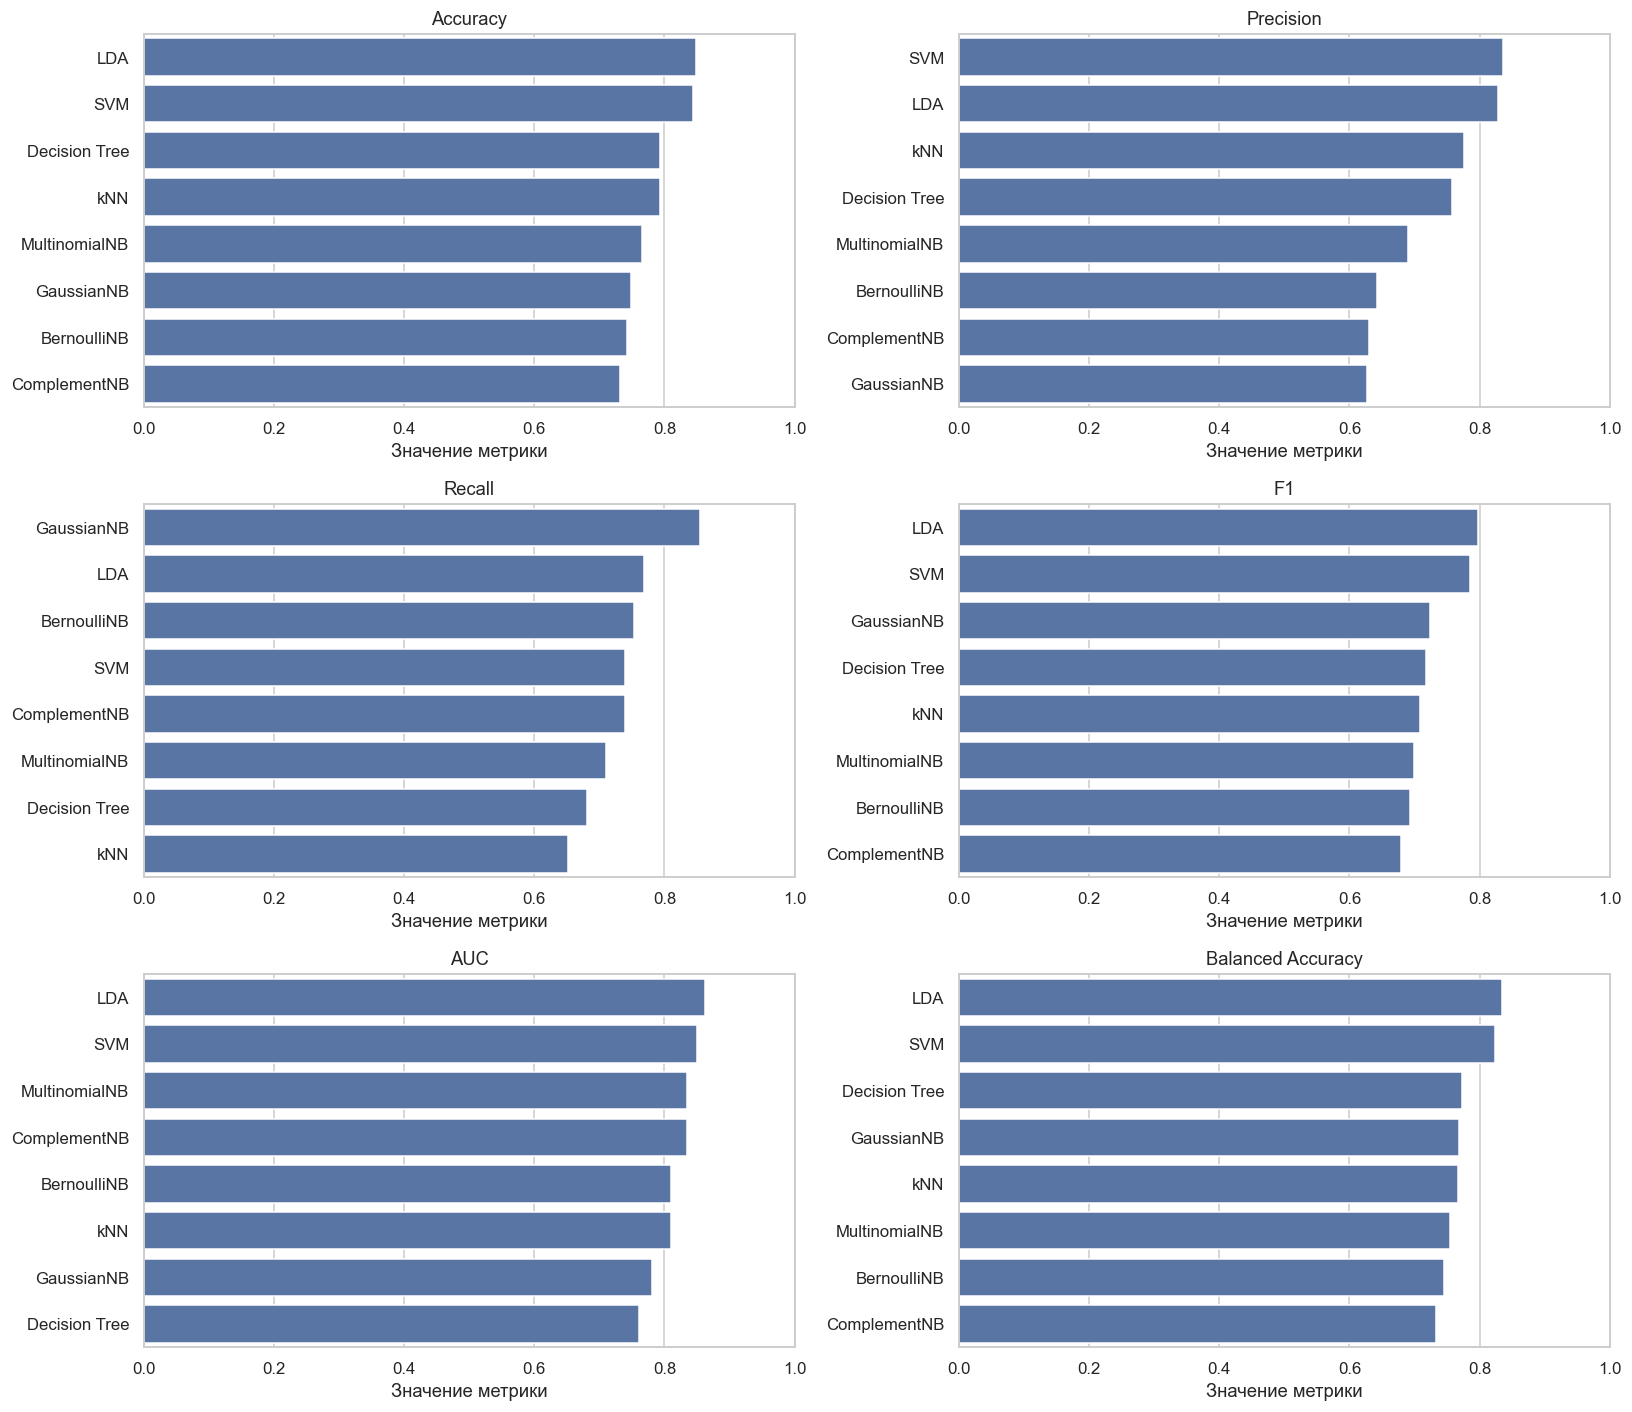

In [11]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "AUC", "Balanced Accuracy"]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, metric in zip(axes.flat, metrics_to_plot):
    values = baseline_df[metric].sort_values(ascending=False)
    sns.barplot(x=values.values, y=values.index, ax=ax)
    ax.set_title(metric)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Значение метрики")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


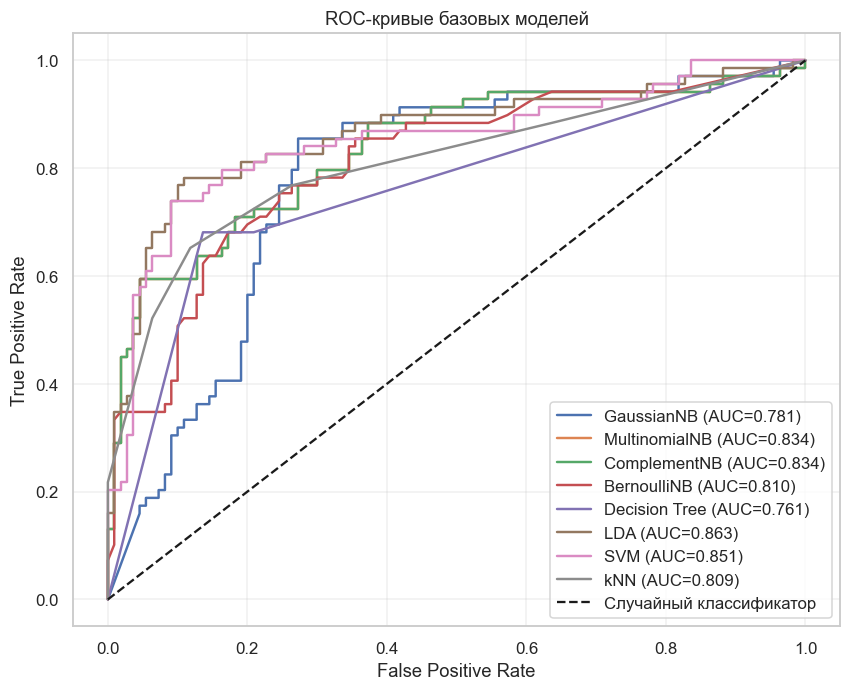

In [12]:
plt.figure(figsize=(9, 7))
for model_name, model in fitted_base.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(model, X_test))
    auc_value = baseline_df.loc[model_name, "AUC"]
    plt.plot(fpr, tpr, linewidth=1.6, label=f"{model_name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые базовых моделей")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()


In [13]:
best_base_auc = baseline_df["AUC"].idxmax()
best_base_f1 = baseline_df["F1"].idxmax()

display(Markdown(
    f"""
**Краткий вывод по базовым моделям.** По ROC-AUC лидирует **{best_base_auc}**
({baseline_df.loc[best_base_auc, "AUC"]:.3f}). Наибольший F1-score показывает
**{best_base_f1}** ({baseline_df.loc[best_base_f1, "F1"]:.3f}).
Разница между Accuracy и Balanced Accuracy показывает, насколько результат
зависит от более частого класса «не выжил».
"""
))



**Краткий вывод по базовым моделям.** По ROC-AUC лидирует **LDA**
(0.863). Наибольший F1-score показывает
**LDA** (0.797).
Разница между Accuracy и Balanced Accuracy показывает, насколько результат
зависит от более частого класса «не выжил».


## Настройка гиперпараметров

Для каждого алгоритма используется 5-блочная стратифицированная кросс-валидация на обучающей выборке. Основная метрика выбора — ROC-AUC. После выбора лучшей комбинации параметров модель один раз оценивается на тестовой части.


In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_scoring = {
    "AUC": "roc_auc",
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
}


def joint_grid_search(model_name, estimator, scaling, param_grid):
    pipeline = make_pipeline(estimator, scaling)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=cv_scoring,
        refit="AUC",
        cv=cv,
        n_jobs=N_JOBS,
        return_train_score=False,
    )
    search.fit(X_train, y_train)

    raw_results = pd.DataFrame(search.cv_results_)
    view = pd.DataFrame({
        "Параметры": raw_results["params"].map(format_params),
        "CV ROC-AUC": raw_results["mean_test_AUC"],
        "CV Accuracy": raw_results["mean_test_Accuracy"],
        "CV Precision": raw_results["mean_test_Precision"],
        "CV Recall": raw_results["mean_test_Recall"],
        "CV F1": raw_results["mean_test_F1"],
    }).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)

    return search, view


def show_top_configs(model_name, top_n=5):
    table = sweep_results[model_name].head(top_n).copy()
    display(Markdown(f"**{model_name}: {len(sweep_results[model_name])} комбинаций.**"))
    with pd.option_context("display.max_colwidth", None):
        display(table.round(4))

    best = table.iloc[0]
    display(Markdown(
        f"Лучшая комбинация по CV ROC-AUC: {best['Параметры']}. "
        f"Средний CV ROC-AUC = {best['CV ROC-AUC']:.4f}."
    ))


### Сетки гиперпараметров

- GaussianNB: var_smoothing.
- MultinomialNB: alpha и fit_prior.
- ComplementNB: alpha и norm.
- BernoulliNB: alpha, binarize и fit_prior.
- Decision Tree: criterion, max_depth, min_samples_leaf, class_weight.
- LDA: shrinkage.
- SVM: C, kernel, gamma, class_weight.
- kNN: n_neighbors, weights и metric.

Параметры подобраны так, чтобы показать влияние регуляризации, сложности модели и способа измерения расстояния без чрезмерно долгого вычисления.


In [31]:
tuning_specs = {
    "GaussianNB": (
        GaussianNB(),
        "standard",
        {
            "classifier__var_smoothing": list(np.logspace(-12, -1, 12)),
        },
    ),
    "MultinomialNB": (
        MultinomialNB(),
        "minmax",
        {
            "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
            "classifier__fit_prior": [True, False],
        },
    ),
    "ComplementNB": (
        ComplementNB(),
        "minmax",
        {
            "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
            "classifier__norm": [False, True],
        },
    ),
    "BernoulliNB": (
        BernoulliNB(),
        "standard",
        {
            "classifier__alpha": [0.1, 0.5, 1.0, 2.0, 5.0],
            "classifier__binarize": [0.0, 0.5, 1.0, 1.5],
            "classifier__fit_prior": [True, False],
        },
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        "none",
        {
            "classifier__criterion": ["gini", "entropy"],
            "classifier__max_depth": [2, 3, 4, 5, None],
            "classifier__min_samples_leaf": [1, 5, 10, 20],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "LDA": (
        LinearDiscriminantAnalysis(solver="lsqr"),
        "standard",
        {
            "classifier__shrinkage": [None, "auto", 0.1, 0.3, 0.5, 0.7, 0.9],
        },
    ),
    "SVM": (
        SVC(random_state=SEED),
        "standard",
        {
            "classifier__C": [0.1, 1, 10, 50],
            "classifier__kernel": ["linear", "rbf"],
            "classifier__gamma": ["scale", 0.01, 0.1],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "kNN": (
        KNeighborsClassifier(),
        "standard",
        {
            "classifier__n_neighbors": [1, 3, 5, 7, 9, 15, 21],
            "classifier__weights": ["uniform", "distance"],
            "classifier__metric": ["euclidean", "manhattan", "chebyshev"],
        },
    ),
}

sweep_results = {}
fitted_tuned = {}
tuned_rows = []

for model_name, (estimator, scaling, param_grid) in tuning_specs.items():
    print(f"Подбор параметров: {model_name}")
    search, table = joint_grid_search(model_name, estimator, scaling, param_grid)

    sweep_results[model_name] = table
    fitted_tuned[model_name] = search.best_estimator_

    test_metrics = evaluate_model(search.best_estimator_, X_test, y_test)
    tuned_rows.append({
        "Модель": model_name,
        "CV ROC-AUC": search.best_score_,
        "Лучшие параметры": format_params(search.best_params_),
        **test_metrics,
    })

tuned_df = (
    pd.DataFrame(tuned_rows)
    .set_index("Модель")
    .sort_values("AUC", ascending=False)
)

print("Подбор завершён.")
with pd.option_context("display.max_colwidth", None):
    display(tuned_df.round(3))


Подбор параметров: GaussianNB
Подбор параметров: MultinomialNB
Подбор параметров: ComplementNB
Подбор параметров: BernoulliNB
Подбор параметров: Decision Tree
Подбор параметров: LDA
Подбор параметров: SVM
Подбор параметров: kNN
Подбор завершён.


,CV ROC-AUC,Лучшие параметры,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,TN,FP,FN,TP
Модель,,,,,,,,,,,,,
LDA,0.876,shrinkage=0.1,0.821,0.803,0.710,0.754,0.861,0.891,0.801,98,12,20,49
kNN,0.868,"metric=manhattan, n_neighbors=15, weights=uniform",0.816,0.860,0.623,0.723,0.851,0.936,0.780,103,7,26,43
Decision Tree,0.865,"class_weight=balanced, criterion=entropy, max_depth=4, min_samples_leaf=1",0.788,0.670,0.884,0.762,0.849,0.727,0.806,80,30,8,61
GaussianNB,0.861,var_smoothing=0.1,0.771,0.694,0.725,0.709,0.849,0.800,0.762,88,22,19,50
SVM,0.870,"C=1, class_weight=balanced, gamma=0.01, kernel=rbf",0.821,0.794,0.725,0.758,0.844,0.882,0.803,97,13,19,50
MultinomialNB,0.857,"alpha=1.0, fit_prior=True",0.765,0.690,0.710,0.700,0.834,0.800,0.755,88,22,20,49
ComplementNB,0.857,"alpha=1.0, norm=False",0.732,0.630,0.739,0.680,0.834,0.727,0.733,80,30,18,51
BernoulliNB,0.851,"alpha=5.0, binarize=0.0, fit_prior=True",0.743,0.642,0.754,0.693,0.810,0.736,0.745,81,29,17,52


### GaussianNB

Параметр var_smoothing добавляет небольшую величину к дисперсиям признаков. Он уменьшает нестабильность оценок, особенно когда признаки сильно различаются по масштабу или распределению.


In [16]:
show_top_configs("GaussianNB")


**GaussianNB: 12 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,var_smoothing=0.1,0.8615,0.8020,0.7446,0.7473,0.7437
1,var_smoothing=0.01,0.8413,0.7964,0.7065,0.8134,0.7546
2,var_smoothing=0.001,0.8279,0.7908,0.6985,0.8096,0.7484
3,var_smoothing=1e-09,0.8252,0.7012,0.6149,0.8717,0.7090
4,var_smoothing=1e-08,0.8249,0.7418,0.6358,0.8499,0.7230


Лучшая комбинация по CV ROC-AUC: var_smoothing=0.1. Средний CV ROC-AUC = 0.8615.

### MultinomialNB

Параметр alpha задаёт силу сглаживания вероятностей, а fit_prior определяет, учитываются ли априорные вероятности классов. Для этой модели числовые признаки масштабируются в диапазон от 0 до 1, так как MultinomialNB не принимает отрицательные значения.


In [17]:
show_top_configs("MultinomialNB")


**MultinomialNB: 14 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"alpha=1.0, fit_prior=False",0.8568,0.7894,0.7004,0.7951,0.7434
1,"alpha=1.0, fit_prior=True",0.8568,0.7922,0.7176,0.7620,0.7377
2,"alpha=2.0, fit_prior=False",0.8566,0.7936,0.7115,0.7840,0.7445
3,"alpha=2.0, fit_prior=True",0.8566,0.7950,0.7251,0.7547,0.7384
4,"alpha=5.0, fit_prior=False",0.8565,0.7950,0.7164,0.7767,0.7440


Лучшая комбинация по CV ROC-AUC: alpha=1.0, fit_prior=False. Средний CV ROC-AUC = 0.8568.

### ComplementNB

ComplementNB использует информацию о дополнении каждого класса и часто применяется при несбалансированных данных. Параметр norm определяет, выполняется ли дополнительная нормализация весов.


In [18]:
show_top_configs("ComplementNB")


**ComplementNB: 14 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"alpha=1.0, norm=False",0.8568,0.7894,0.7004,0.7951,0.7434
1,"alpha=2.0, norm=False",0.8566,0.7936,0.7115,0.7840,0.7445
2,"alpha=5.0, norm=False",0.8565,0.7950,0.7164,0.7767,0.7440
3,"alpha=0.5, norm=False",0.8563,0.7880,0.6985,0.7951,0.7422
4,"alpha=10.0, norm=False",0.8562,0.7964,0.7251,0.7620,0.7416


Лучшая комбинация по CV ROC-AUC: alpha=1.0, norm=False. Средний CV ROC-AUC = 0.8568.

### BernoulliNB

BernoulliNB работает с бинаризованными признаками. Параметр binarize задаёт порог: значения выше порога становятся единицами, остальные — нулями. Alpha отвечает за сглаживание.


In [19]:
show_top_configs("BernoulliNB")


**BernoulliNB: 40 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"alpha=5.0, binarize=0.0, fit_prior=False",0.8514,0.7810,0.6897,0.7914,0.7353
1,"alpha=5.0, binarize=0.0, fit_prior=True",0.8514,0.7936,0.7099,0.7877,0.7454
2,"alpha=0.1, binarize=0.5, fit_prior=False",0.8512,0.7810,0.6885,0.7914,0.7351
3,"alpha=0.1, binarize=0.5, fit_prior=True",0.8512,0.7852,0.6992,0.7803,0.7360
4,"alpha=0.5, binarize=0.5, fit_prior=True",0.8512,0.7852,0.6992,0.7803,0.7360


Лучшая комбинация по CV ROC-AUC: alpha=5.0, binarize=0.0, fit_prior=False. Средний CV ROC-AUC = 0.8514.

### Дерево решений

criterion выбирает критерий разбиения, max_depth ограничивает глубину дерева, min_samples_leaf задаёт минимальный размер листа, class_weight компенсирует разную численность классов. Ограничение глубины и размера листа уменьшает риск переобучения.


In [33]:
show_top_configs("Decision Tree")


**Decision Tree: 80 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"class_weight=balanced, criterion=entropy, max_depth=4, min_samples_leaf=1",0.8652,0.8119,0.7200,0.8387,0.7743
1,"class_weight=balanced, criterion=entropy, max_depth=4, min_samples_leaf=5",0.8620,0.8007,0.7021,0.8461,0.7664
2,"class_weight=balanced, criterion=entropy, max_depth=5, min_samples_leaf=5",0.8614,0.7992,0.7368,0.7546,0.7420
3,"class_weight=balanced, criterion=entropy, max_depth=5, min_samples_leaf=1",0.8591,0.8020,0.7539,0.7290,0.7383
4,"class_weight=None, criterion=gini, max_depth=3, min_samples_leaf=5",0.8587,0.8202,0.7959,0.7366,0.7588


Лучшая комбинация по CV ROC-AUC: class_weight=balanced, criterion=entropy, max_depth=4, min_samples_leaf=1. Средний CV ROC-AUC = 0.8652.

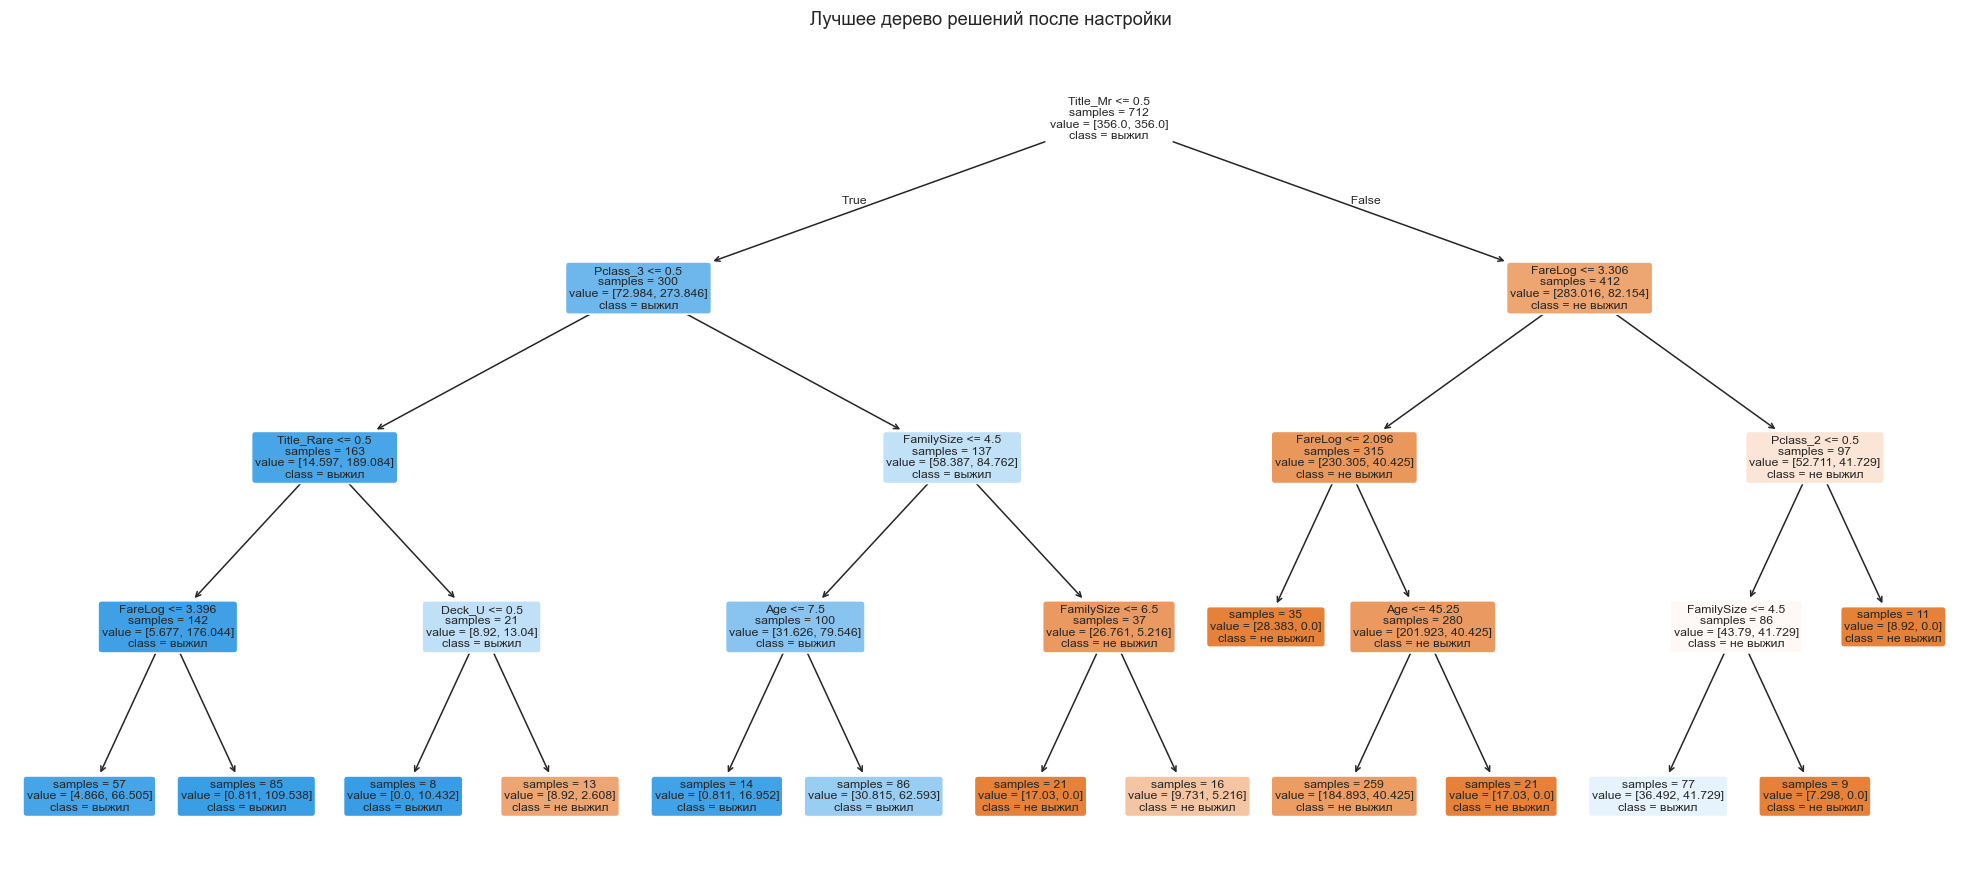

In [21]:
best_tree = fitted_tuned["Decision Tree"]
tree_features = best_tree.named_steps["preprocessor"].get_feature_names_out()
tree_features = [
    name.replace("num__", "").replace("cat__", "")
    for name in tree_features
]

fig, ax = plt.subplots(figsize=(23, 10))
plot_tree(
    best_tree.named_steps["classifier"],
    feature_names=tree_features,
    class_names=["не выжил", "выжил"],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=False,
    fontsize=8,
    ax=ax,
)
ax.set_title("Лучшее дерево решений после настройки")
plt.show()


### Линейный дискриминантный анализ

Параметр shrinkage регуляризует оценку ковариационной матрицы. Регуляризация может сделать LDA устойчивее при коррелированных признаках и большом числе закодированных категорий.


In [22]:
show_top_configs("LDA")


**LDA: 7 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,shrinkage=0.1,0.8758,0.8174,0.7747,0.7474,0.7591
1,shrinkage=0.3,0.8745,0.8048,0.7500,0.7400,0.7441
2,shrinkage=auto,0.8744,0.8132,0.7638,0.7475,0.7543
3,shrinkage=0.5,0.8720,0.8020,0.7443,0.7437,0.7425
4,shrinkage=None,0.8666,0.8161,0.7755,0.7401,0.7551


Лучшая комбинация по CV ROC-AUC: shrinkage=0.1. Средний CV ROC-AUC = 0.8758.

### Метод опорных векторов

C регулирует штраф за ошибки, kernel определяет тип границы решения, gamma управляет радиусом влияния объектов для RBF-ядра. Параметр class_weight позволяет увеличить влияние менее частого класса выживших.


In [23]:
show_top_configs("SVM")


**SVM: 48 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"C=1, class_weight=balanced, gamma=0.01, kernel...",0.8697,0.8104,0.7679,0.7253,0.7450
1,"C=0.1, class_weight=balanced, gamma=scale, ker...",0.8644,0.7992,0.7295,0.7694,0.7462
2,"C=0.1, class_weight=balanced, gamma=0.1, kerne...",0.8644,0.7992,0.7295,0.7694,0.7462
3,"C=0.1, class_weight=balanced, gamma=0.01, kern...",0.8644,0.7992,0.7295,0.7694,0.7462
4,"C=0.1, class_weight=None, gamma=0.01, kernel=rbf",0.8636,0.7107,0.9846,0.2491,0.3963


Лучшая комбинация по CV ROC-AUC: C=1, class_weight=balanced, gamma=0.01, kernel=rbf. Средний CV ROC-AUC = 0.8697.

### Метод k ближайших соседей

n_neighbors задаёт число соседей, weights — схему их взвешивания, metric — способ измерять расстояние. Масштабирование числовых признаков необходимо, чтобы стоимость билета и возраст не доминировали над остальными признаками.


In [24]:
show_top_configs("kNN")


**kNN: 42 комбинаций.**

,Параметры,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,"metric=manhattan, n_neighbors=15, weights=uniform",0.8676,0.8146,0.8320,0.6522,0.7293
1,"metric=manhattan, n_neighbors=9, weights=uniform",0.8659,0.8091,0.8093,0.6667,0.7285
2,"metric=euclidean, n_neighbors=15, weights=uniform",0.8638,0.8118,0.8135,0.6667,0.7315
3,"metric=euclidean, n_neighbors=7, weights=uniform",0.8614,0.8118,0.8015,0.6888,0.7379
4,"metric=manhattan, n_neighbors=21, weights=uniform",0.8607,0.8132,0.8124,0.6738,0.7342


Лучшая комбинация по CV ROC-AUC: metric=manhattan, n_neighbors=15, weights=uniform. Средний CV ROC-AUC = 0.8676.

## Сравнение базовых и настроенных классических моделей


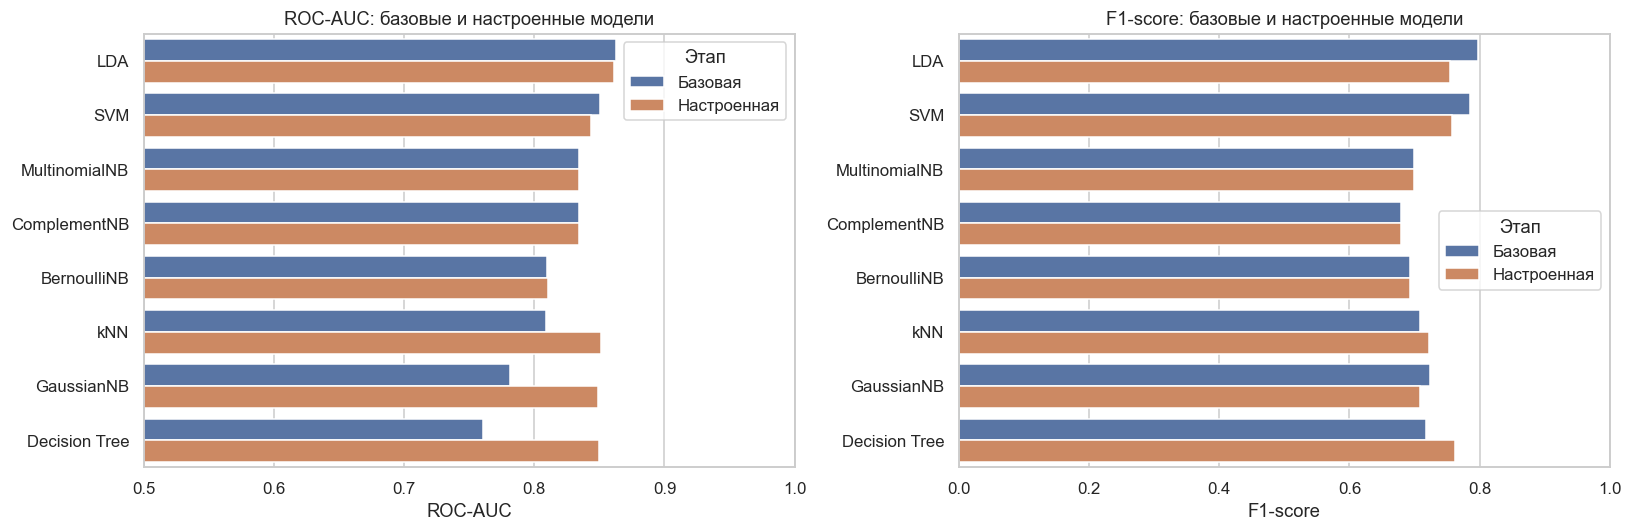

In [25]:
comparison_long = pd.concat([
    baseline_df[["Accuracy", "Precision", "Recall", "F1", "AUC"]]
        .assign(Модель=lambda frame: frame.index, Этап="Базовая"),
    tuned_df[["Accuracy", "Precision", "Recall", "F1", "AUC"]]
        .assign(Модель=lambda frame: frame.index, Этап="Настроенная"),
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=comparison_long,
    x="AUC",
    y="Модель",
    hue="Этап",
    ax=axes[0],
)
axes[0].set_title("ROC-AUC: базовые и настроенные модели")
axes[0].set_xlim(0.5, 1)
axes[0].set_xlabel("ROC-AUC")
axes[0].set_ylabel("")

sns.barplot(
    data=comparison_long,
    x="F1",
    y="Модель",
    hue="Этап",
    ax=axes[1],
)
axes[1].set_title("F1-score: базовые и настроенные модели")
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("F1-score")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [26]:
best_tuned_auc = tuned_df["AUC"].idxmax()
best_tuned_f1 = tuned_df["F1"].idxmax()

display(Markdown(
    f"""
**Вывод по настройке классических моделей.** На тестовой выборке наибольший
ROC-AUC среди настроенных моделей у **{best_tuned_auc}**
({tuned_df.loc[best_tuned_auc, "AUC"]:.3f}). Наибольший F1-score у
**{best_tuned_f1}** ({tuned_df.loc[best_tuned_f1, "F1"]:.3f}).

ROC-AUC кросс-валидации использовался для выбора параметров, а тестовые
метрики показывают обобщающую способность моделей на 179 ранее не виденных
пассажирах.
"""
))



**Вывод по настройке классических моделей.** На тестовой выборке наибольший
ROC-AUC среди настроенных моделей у **LDA**
(0.861). Наибольший F1-score у
**Decision Tree** (0.762).

ROC-AUC кросс-валидации использовался для выбора параметров, а тестовые
метрики показывают обобщающую способность моделей на 179 ранее не виденных
пассажирах.


## Нейронная сеть TensorFlow

Следующие ячейки требуют установленный TensorFlow. Если импорт ниже завершается ошибкой ModuleNotFoundError, выполните команду установки из раздела «Как открыть и запустить в VS Code», затем перезапустите ядро.


In [28]:
try:
    import tensorflow as tf
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        "Не найден TensorFlow. В терминале VS Code выполните: "
        "python -m pip install tensorflow tensorboard"
    ) from error

from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## Подготовка данных для нейронной сети

Обучающая часть дополнительно делится на обучение и валидацию в пропорции 80 % / 20 %. Преобразователь признаков обучается только на обучающей части X_tr; это исключает утечку информации из валидации и теста.


In [29]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train,
)

preprocessor_nn = make_preprocessor("standard")
X_tr_nn = np.asarray(
    preprocessor_nn.fit_transform(X_tr),
    dtype=np.float32,
)
X_val_nn = np.asarray(
    preprocessor_nn.transform(X_val),
    dtype=np.float32,
)
X_test_nn = np.asarray(
    preprocessor_nn.transform(X_test),
    dtype=np.float32,
)

classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_tr,
)
class_weight_nn = {int(label): float(weight) for label, weight in zip(classes, weights)}

print("Форма X_tr:", X_tr_nn.shape)
print("Форма X_val:", X_val_nn.shape)
print("Форма X_test:", X_test_nn.shape)
print("Веса классов:", class_weight_nn)


Форма X_tr: (569, 28)
Форма X_val: (143, 28)
Форма X_test: (179, 28)
Веса классов: {0: 0.8105413105413105, 1: 1.305045871559633}


## Архитектура нейронной сети

Используется полносвязная сеть прямого распространения. На вход подаются масштабированные числовые признаки и one-hot кодированные категории. Скрытые слои используют ReLU или tanh, а выходной слой с одним нейроном и сигмоидальной активацией выдаёт вероятность выживания. Функция потерь — binary crossentropy, оптимизатор — Adam, ключевая метрика выбора — ROC-AUC.


In [30]:
def build_model(
    input_dim,
    hidden_layers=(32, 16),
    activation="relu",
    learning_rate=0.001,
    dropout=0.0,
):
    model = tf.keras.Sequential(name="titanic_classifier")
    model.add(tf.keras.layers.Input(shape=(input_dim,)))

    for units in hidden_layers:
        model.add(tf.keras.layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))

    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )
    return model


demo_model = build_model(input_dim=X_tr_nn.shape[1])
demo_model.summary()


Model: "titanic_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,473 (5.75 KB)

 Trainable params: 1,473 (5.75 KB)

 Non-trainable params: 0 (0.00 B)

## Эксперименты с гиперпараметрами

В каждом эксперименте меняется один или несколько параметров архитектуры: число нейронов, функция активации, скорость обучения или dropout. Для остановки обучения используется EarlyStopping с восстановлением лучших весов по val_loss. Журналы каждого эксперимента сохраняются в папке logs/titanic.


In [36]:
from datetime import datetime
from pathlib import Path
import tempfile

LOG_ROOT = Path(tempfile.gettempdir()) / "titanic_tensorboard"
LOG_DIR = LOG_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
LOG_DIR.mkdir(parents=True, exist_ok=False)
print("Папка логов TensorBoard:", LOG_DIR)

NN_CONFIGS = {
    "A. Базовая": {
        "hidden_layers": (32, 16),
        "activation": "relu",
        "learning_rate": 0.001,
        "dropout": 0.0,
        "batch_size": 32,
        "epochs": 80,
    },
    "B. Меньшая сеть": {
        "hidden_layers": (16,),
        "activation": "relu",
        "learning_rate": 0.001,
        "dropout": 0.0,
        "batch_size": 32,
        "epochs": 80,
    },
    "C. Более широкая сеть": {
        "hidden_layers": (64, 32),
        "activation": "relu",
        "learning_rate": 0.001,
        "dropout": 0.0,
        "batch_size": 32,
        "epochs": 80,
    },
    "D. Tanh": {
        "hidden_layers": (32, 16),
        "activation": "tanh",
        "learning_rate": 0.001,
        "dropout": 0.0,
        "batch_size": 32,
        "epochs": 80,
    },
    "E. Меньший learning rate": {
        "hidden_layers": (32, 16),
        "activation": "relu",
        "learning_rate": 0.0003,
        "dropout": 0.0,
        "batch_size": 32,
        "epochs": 80,
    },
    "F. Dropout 0.20": {
        "hidden_layers": (32, 16),
        "activation": "relu",
        "learning_rate": 0.001,
        "dropout": 0.20,
        "batch_size": 32,
        "epochs": 80,
    },
}

nn_histories = {}
nn_models = {}
nn_rows = []

for label, config in NN_CONFIGS.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(
        input_dim=X_tr_nn.shape[1],
        hidden_layers=config["hidden_layers"],
        activation=config["activation"],
        learning_rate=config["learning_rate"],
        dropout=config["dropout"],
    )

    run_id = label.split(".", 1)[0]  # A, B, C, D, E или F
    run_dir = LOG_DIR / run_id
    run_dir.mkdir(exist_ok=True)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.TensorBoard(
            log_dir=run_dir.as_posix(),
            histogram_freq=0,
            update_freq="epoch",
        ),
    ]

    history = model.fit(
        X_tr_nn,
        y_tr,
        validation_data=(X_val_nn, y_val),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        class_weight=class_weight_nn,
        callbacks=callbacks,
        verbose=0,
    )

    val_score = model.predict(X_val_nn, verbose=0).ravel()
    val_pred = (val_score >= 0.5).astype(int)

    nn_histories[label] = history
    nn_models[label] = model
    nn_rows.append({
        "Эксперимент": label,
        "Слои": str(config["hidden_layers"]),
        "Активация": config["activation"],
        "Learning rate": config["learning_rate"],
        "Dropout": config["dropout"],
        "Эпох выполнено": len(history.history["loss"]),
        "Val Accuracy": accuracy_score(y_val, val_pred),
        "Val F1": f1_score(y_val, val_pred, zero_division=0),
        "Val ROC-AUC": roc_auc_score(y_val, val_score),
    })

nn_results_df = (
    pd.DataFrame(nn_rows)
    .set_index("Эксперимент")
    .sort_values("Val ROC-AUC", ascending=False)
)
display(nn_results_df.round(3))


Папка логов TensorBoard: C:\Users\7636~1\AppData\Local\Temp\titanic_tensorboard\20261113_101925_573530


,Слои,Активация,Learning rate,Dropout,Эпох выполнено,Val Accuracy,Val F1,Val ROC-AUC
Эксперимент,,,,,,,,
F. Dropout 0.20,"(32, 16)",relu,0.001,0.2,27,0.818,0.768,0.874
C. Более широкая сеть,"(64, 32)",relu,0.001,0.0,20,0.818,0.768,0.873
D. Tanh,"(32, 16)",tanh,0.001,0.0,18,0.797,0.739,0.871
A. Базовая,"(32, 16)",relu,0.001,0.0,23,0.811,0.761,0.868
E. Меньший learning rate,"(32, 16)",relu,0.000,0.0,46,0.804,0.754,0.867
B. Меньшая сеть,"(16,)",relu,0.001,0.0,30,0.783,0.735,0.867


In [37]:
best_nn_label = nn_results_df["Val ROC-AUC"].idxmax()
nn_model = nn_models[best_nn_label]
nn_history = nn_histories[best_nn_label]

nn_test_score = nn_model.predict(X_test_nn, verbose=0).ravel()
nn_test_pred = (nn_test_score >= 0.5).astype(int)
nn_metrics = calculate_metrics(y_test, nn_test_pred, nn_test_score)

display(Markdown(
    f"""
**Выбранная конфигурация:** {best_nn_label}. Она имеет наибольший
валидационный ROC-AUC: {nn_results_df.loc[best_nn_label, "Val ROC-AUC"]:.3f}.
Тестовая выборка использована только после выбора конфигурации.
"""
))

display(pd.DataFrame([nn_metrics], index=["Нейронная сеть"]).round(3))



**Выбранная конфигурация:** F. Dropout 0.20. Она имеет наибольший
валидационный ROC-AUC: 0.874.
Тестовая выборка использована только после выбора конфигурации.


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,TN,FP,FN,TP
Нейронная сеть,0.816,0.743,0.797,0.769,0.848,0.827,0.812,91,19,14,55


## Графики обучения выбранной нейронной сети


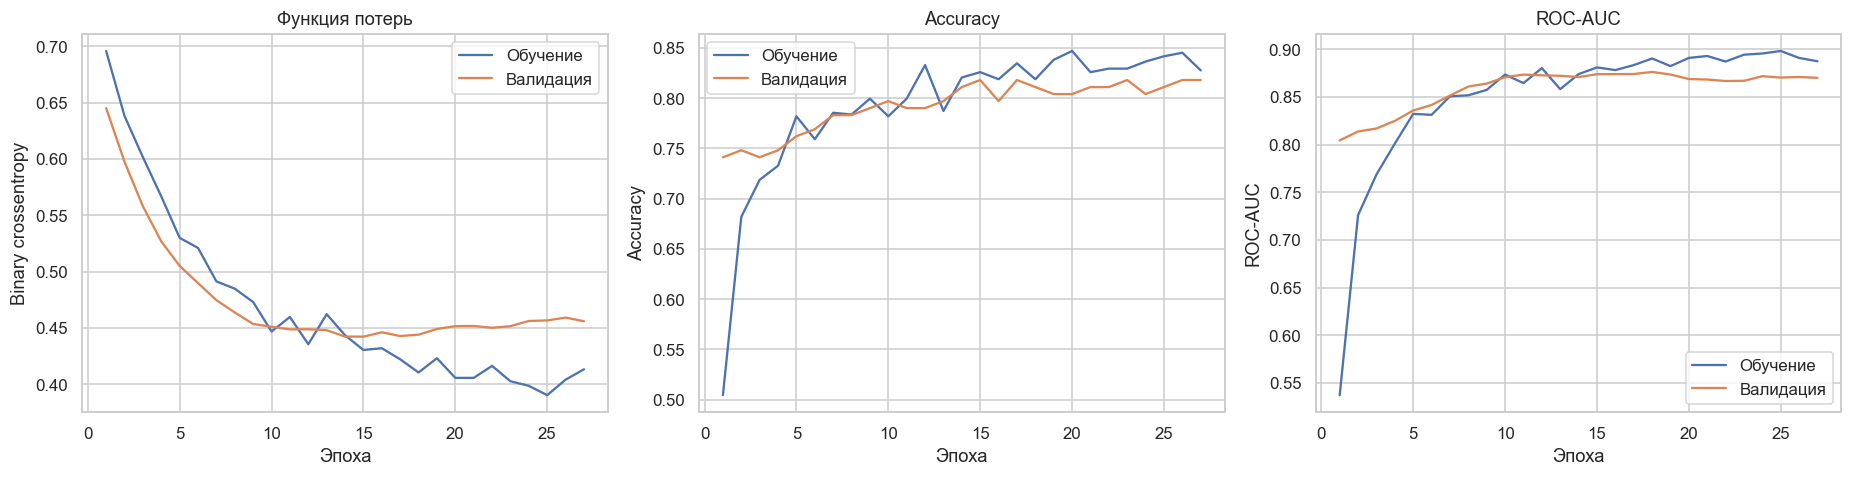

In [38]:
history = nn_history.history
epochs_range = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(epochs_range, history["loss"], label="Обучение")
axes[0].plot(epochs_range, history["val_loss"], label="Валидация")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()

axes[1].plot(epochs_range, history["accuracy"], label="Обучение")
axes[1].plot(epochs_range, history["val_accuracy"], label="Валидация")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

axes[2].plot(epochs_range, history["auc"], label="Обучение")
axes[2].plot(epochs_range, history["val_auc"], label="Валидация")
axes[2].set_title("ROC-AUC")
axes[2].set_xlabel("Эпоха")
axes[2].set_ylabel("ROC-AUC")
axes[2].legend()

plt.tight_layout()
plt.show()


In [39]:
last_epoch = len(history["loss"]) - 1
display(Markdown(
    f"""
**Интерпретация обучения.** После {last_epoch + 1} эпох значение val_loss равно
{history["val_loss"][last_epoch]:.4f}, val_accuracy — {history["val_accuracy"][last_epoch]:.4f},
val_auc — {history["val_auc"][last_epoch]:.4f}. Для оценки переобучения нужно
сравнить расстояние между обучающими и валидационными кривыми: устойчиво
растущий разрыв означает ухудшение способности обобщать данные.
"""
))



**Интерпретация обучения.** После 27 эпох значение val_loss равно
0.4559, val_accuracy — 0.8182,
val_auc — 0.8699. Для оценки переобучения нужно
сравнить расстояние между обучающими и валидационными кривыми: устойчиво
растущий разрыв означает ухудшение способности обобщать данные.


## TensorBoard

После выполнения экспериментов можно просмотреть графики обучения. В интерактивном notebook VS Code выполните следующую ячейку. Если встроенное отображение не откроется, запустите в терминале VS Code команду:

python -m tensorboard.main --logdir logs/titanic --port 6006

Затем откройте ссылку, которую выведет TensorBoard.


In [49]:
%load_ext tensorboard
%tensorboard --logdir "E:/Lab2_ML/titanic_tensorboard/20261113_093130_458005" 


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6007 (pid 13208), started 0:00:03 ago. (Use '!kill 13208' to kill it.)

## Сравнительный анализ всех настроенных методов


In [50]:
final_rows = []

for model_name, row in tuned_df.iterrows():
    final_rows.append({
        "Модель": model_name,
        "Тип": "Классическая",
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1": row["F1"],
        "AUC": row["AUC"],
        "Specificity": row["Specificity"],
        "Balanced Accuracy": row["Balanced Accuracy"],
    })

final_rows.append({
    "Модель": "Нейронная сеть (TensorFlow)",
    "Тип": "Нейронная сеть",
    **{key: nn_metrics[key] for key in [
        "Accuracy", "Precision", "Recall", "F1", "AUC",
        "Specificity", "Balanced Accuracy"
    ]},
})

final_comparison_df = (
    pd.DataFrame(final_rows)
    .set_index("Модель")
    .sort_values("AUC", ascending=False)
)

display(final_comparison_df.round(3))


,Тип,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy
Модель,,,,,,,,
LDA,Классическая,0.821,0.803,0.710,0.754,0.861,0.891,0.801
kNN,Классическая,0.816,0.860,0.623,0.723,0.851,0.936,0.780
Decision Tree,Классическая,0.788,0.670,0.884,0.762,0.849,0.727,0.806
GaussianNB,Классическая,0.771,0.694,0.725,0.709,0.849,0.800,0.762
Нейронная сеть (TensorFlow),Нейронная сеть,0.816,0.743,0.797,0.769,0.848,0.827,0.812
SVM,Классическая,0.821,0.794,0.725,0.758,0.844,0.882,0.803
MultinomialNB,Классическая,0.765,0.690,0.710,0.700,0.834,0.800,0.755
ComplementNB,Классическая,0.732,0.630,0.739,0.680,0.834,0.727,0.733
BernoulliNB,Классическая,0.743,0.642,0.754,0.693,0.810,0.736,0.745


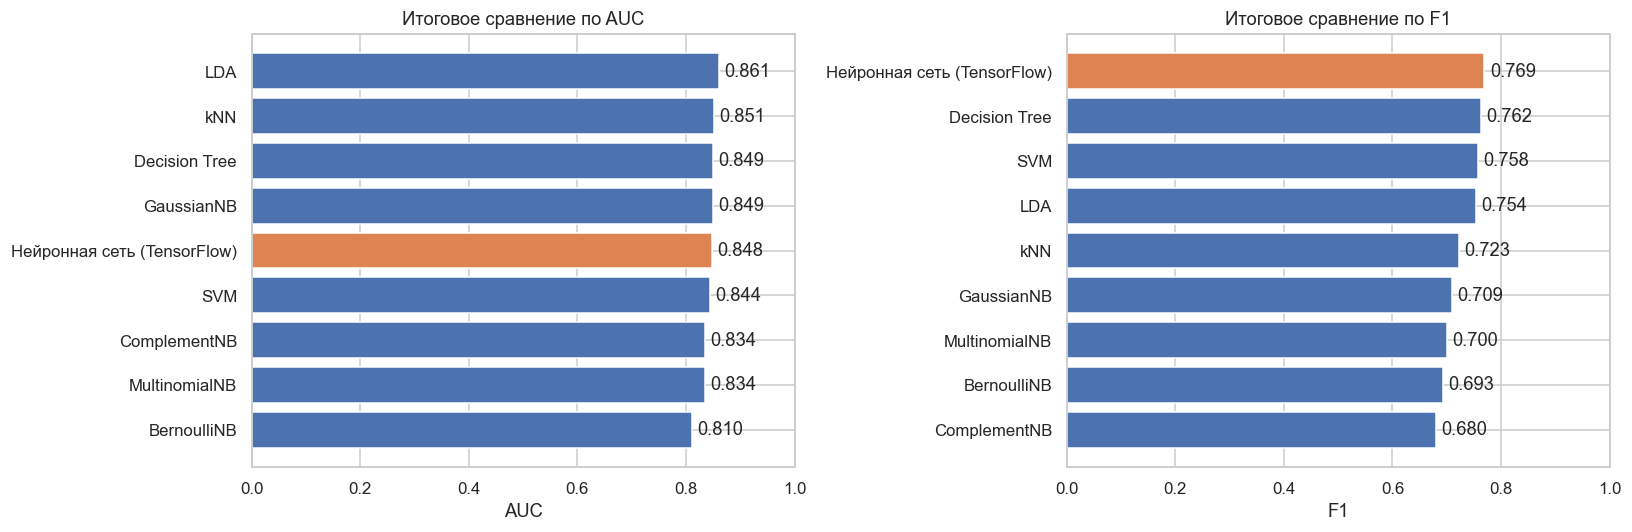

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric in zip(axes, ["AUC", "F1"]):
    values = final_comparison_df[metric].sort_values(ascending=True)
    colors = [
        "#dd8452" if name == "Нейронная сеть (TensorFlow)" else "#4c72b0"
        for name in values.index
    ]
    ax.barh(values.index, values.values, color=colors)
    ax.set_xlim(0, 1)
    ax.set_title(f"Итоговое сравнение по {metric}")
    ax.set_xlabel(metric)
    for index, value in enumerate(values.values):
        ax.text(value + 0.01, index, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()


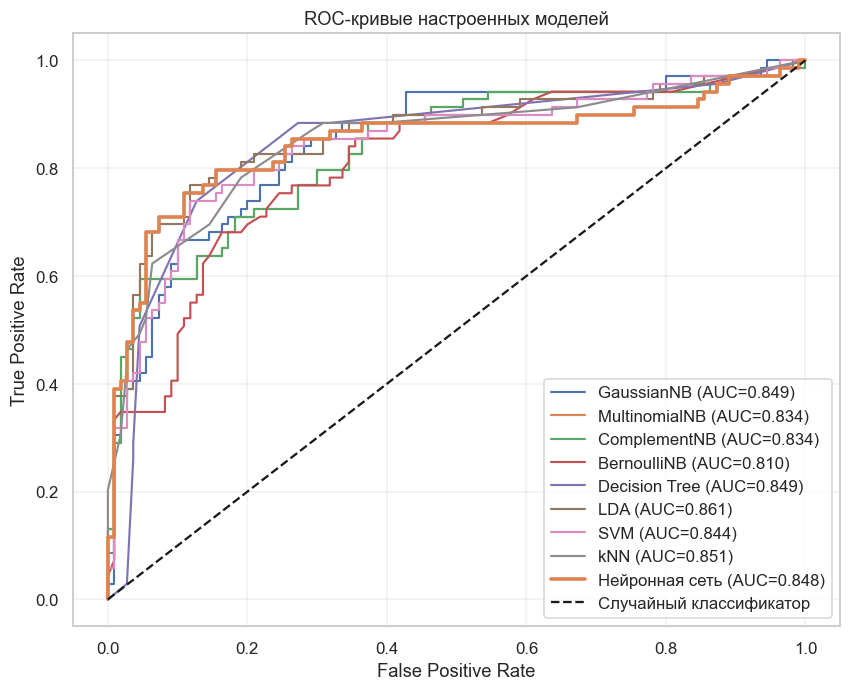

In [52]:
plt.figure(figsize=(9, 7))

for model_name, model in fitted_tuned.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(model, X_test))
    auc_value = tuned_df.loc[model_name, "AUC"]
    plt.plot(fpr, tpr, linewidth=1.4, label=f"{model_name} (AUC={auc_value:.3f})")

fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_test_score)
plt.plot(
    fpr_nn,
    tpr_nn,
    linewidth=2.4,
    color="#dd8452",
    label=f"Нейронная сеть (AUC={nn_metrics['AUC']:.3f})",
)

plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые настроенных моделей")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()


## Заключение


In [53]:
best_overall_auc = final_comparison_df["AUC"].idxmax()
best_overall_f1 = final_comparison_df["F1"].idxmax()

display(Markdown(
    f"""
В ходе лабораторной работы была решена задача бинарной классификации выживания
пассажиров «Титаника» на выборке из {len(df_raw)} наблюдений. Были обнаружены
пропуски в Age, Cabin и Embarked; для их обработки использован конвейер,
который обучается только на обучающих данных. Из исходных текстовых полей были
созданы информативные признаки Title и Deck, а идентификаторы и почти
уникальные значения исключены.

Сравнены восемь классических классификаторов, настроенных с помощью
стратифицированной 5-блочной кросс-валидации, и нейронная сеть TensorFlow.
На общей тестовой выборке лучший ROC-AUC показала модель **{best_overall_auc}**
({final_comparison_df.loc[best_overall_auc, "AUC"]:.3f}), а наибольший
F1-score — **{best_overall_f1}**
({final_comparison_df.loc[best_overall_f1, "F1"]:.3f}).

Результат следует интерпретировать с учётом небольшого размера тестовой
выборки (179 пассажиров). Для практической задачи выбор порога решения нужно
делать по цене ошибок: например, когда важнее не пропустить пассажира с
высокой вероятностью выживания, следует уделить больше внимания Recall.
"""
))



В ходе лабораторной работы была решена задача бинарной классификации выживания
пассажиров «Титаника» на выборке из 891 наблюдений. Были обнаружены
пропуски в Age, Cabin и Embarked; для их обработки использован конвейер,
который обучается только на обучающих данных. Из исходных текстовых полей были
созданы информативные признаки Title и Deck, а идентификаторы и почти
уникальные значения исключены.

Сравнены восемь классических классификаторов, настроенных с помощью
стратифицированной 5-блочной кросс-валидации, и нейронная сеть TensorFlow.
На общей тестовой выборке лучший ROC-AUC показала модель **LDA**
(0.861), а наибольший
F1-score — **Нейронная сеть (TensorFlow)**
(0.769).

Результат следует интерпретировать с учётом небольшого размера тестовой
выборки (179 пассажиров). Для практической задачи выбор порога решения нужно
делать по цене ошибок: например, когда важнее не пропустить пассажира с
высокой вероятностью выживания, следует уделить больше внимания Recall.


## Что приложить к отчёту

1. Скриншоты первичного анализа и распределения классов.
2. Таблицу базовых моделей и ROC-кривые.
3. Таблицу лучшей комбинации параметров после кросс-валидации.
4. Визуализацию дерева решений.
5. Таблицу экспериментов нейронной сети, графики loss, accuracy и AUC.
6. Скриншот TensorBoard.
7. Итоговую таблицу сравнения моделей и заключение.
